# 03 · Growth: how we grow our take over the next 12 months

- **Run-rate** = June–August 2026 (the last three full months), annualised ×365/days, in ETH first, then USD at that period's fee-weighted ETH price (file 01 `total_fee_usd / total_fee_eth`). It is the base, because the trailing year is front-loaded (notebook 01).
- **Net revenue** = execution fees (L1 cost = the L1 data fee charged to users). growthepie's `rent_paid_eth` is used only for the L1 fee-recovery lever.
- **Payer groups** as in notebook 01: **priority** bidders (≥ 0.1 gwei), **botlike** = high-frequency traffic (≥ 1,000 transactions per sender a day), **other**.
- **Floor model:** execution fees with a minimum base fee = priority bidders' fees held flat + Σ over the other two groups of gas × retention × max(floor, today's gas price). Retention applies to high-frequency traffic; other traffic stays at 100% except in one stress case.

Reads `rev_` and `cust_` numbers, so run notebooks 01 and 02 first. Writes every `growth_` number to `output/numbers.json`.

In [1]:
import calendar
import sys
from pathlib import Path

import duckdb
import plotly.graph_objects as go

sys.path.insert(0, str(Path.cwd().parent))  # project root, when run from notebooks/
from src import numbers
from src.build_db import ROOT
from src.charts import figure, show

numbers.clear("growth_")
con = duckdb.connect(str(ROOT / "data" / "opm.duckdb"), read_only=True)

FLOOR_WEI = 2**24        # recommended minimum base fee
BASE_FLOOR_WEI = 5_000_000   # Base mainnet since 2026-02-19
ARB_FLOOR_WEI = 20_000_000   # Arbitrum One since ArbOS 51 (2026-01-08)
ACTIVATION_MONTHS = 3    # governance lead before the floor is live
PAYMENTS_GROWTH = 0.5    # lever 2 base case (low 0%, high 100%)
TRADING_GROWTH = 0.25    # lever 3 base case (low 0%, high 50%)

## What do we earn today, on the June–August 2026 run-rate?

In [2]:
today = con.sql("""
    select count(*) as days,
           sum(execution_fee_eth) as net_eth,
           sum(l1_data_fee_eth) as l1_fee_eth,
           sum(execution_fee_eth) / count(*) as net_eth_per_day,
           sum(execution_fee_eth) * 365 / count(*) as net_eth_per_year,
           sum(execution_fee_eth) * 365 / count(*) / 12 as net_eth_per_month,
           sum(total_fee_usd) / sum(total_fee_eth) as eth_usd,
           sum(execution_fee_eth) * 365 / count(*) * sum(total_fee_usd) / sum(total_fee_eth) as net_usd_per_year
    from fees_daily
    where date between '2026-06-01' and '2026-08-31'
""").df()
now = today.iloc[0]
numbers.record("growth_eth_usd", now["eth_usd"], "fee-weighted ETH price, Jun–Aug 2026 (file 01 total_fee_usd / total_fee_eth)")
numbers.record("growth_baseline_net_usd", now["net_usd_per_year"], "Jun–Aug 2026 net annualised, USD at period fee-weighted price")
numbers.record("growth_baseline_eth_per_day", now["net_eth_per_day"], "Jun–Aug 2026 net (execution fees) ETH per day")
numbers.record("growth_net_eth_per_month_now", now["net_eth_per_month"], "Jun–Aug 2026 net (execution fees) annualised / 12")
today

,days,net_eth,l1_fee_eth,net_eth_per_day,net_eth_per_year,net_eth_per_month,eth_usd,net_usd_per_year
0,92,79.621263,1.047454,0.865449,315.888706,26.324059,1879.014179,593559.358459


## How are gas and execution fees split between priority bidders, high-frequency traffic and the rest?

In [3]:
groups = con.sql("""
    select case when to_address <> 'other' and execution_fee_eth * 1e9 >= 0.1 * gas_used then 'priority'  -- pays >= 0.1 gwei: a tip to go first
                when to_address <> 'other' and txs >= 1000 * distinct_senders then 'botlike'             -- >= 1,000 txs per sender that day
                else 'other' end as payer,
           sum(txs) as txs,
           sum(gas_used)::double as gas,
           sum(execution_fee_eth) as exec_eth,
           sum(execution_fee_eth) * 1e9 / sum(gas_used) as gas_price_gwei,
           sum(gas_used) / sum(sum(gas_used)) over () as gas_share,
           sum(execution_fee_eth) / sum(sum(execution_fee_eth)) over () as exec_share
    from contract_activity
    where date between '2026-06-01' and '2026-08-31'
    group by payer
    order by payer
""").df()
g = groups.set_index("payer")
numbers.record("growth_priority_gas_share", g.loc["priority", "gas_share"], "Jun–Aug 2026 share of gas from priority bidders")
numbers.record("growth_priority_exec_share", g.loc["priority", "exec_share"], "Jun–Aug 2026 share of execution fees from priority bidders")
numbers.record("growth_botlike_gas_share", g.loc["botlike", "gas_share"], "Jun–Aug 2026 share of gas from bot-like destinations")
numbers.record("growth_botlike_gas_price_gwei", g.loc["botlike", "gas_price_gwei"], "Jun–Aug 2026 execution gas price paid by bot-like traffic")
numbers.record("growth_floor_price_multiple_botlike", FLOOR_WEI / 1e9 / g.loc["botlike", "gas_price_gwei"], "floor / bot-like gas price today")
groups

,payer,txs,gas,exec_eth,gas_price_gwei,gas_share,exec_share
0,botlike,127152072.0,3.861287e+13,34.547550,0.000895,0.836244,0.433901
1,other,23647447.0,7.509325e+12,20.553134,0.002737,0.162630,0.258138
2,priority,769706.0,5.199118e+10,24.520151,0.471621,0.001126,0.307961


## Check: do the three groups add up to file 01's execution fees for the period?

In [4]:
gap_eth = groups["exec_eth"].sum() - now["net_eth"]
assert abs(gap_eth) < 0.01  # file 06 rows are rounded to 1e-6 ETH
gap_eth

np.float64(-0.0004280000002978568)

## Lever 1: which minimum base fee?

Jovian added `minBaseFee` to the OP Stack, set with `SystemConfig.setMinBaseFee` ([operator guide](https://docs.optimism.io/chain-operators/guides/features/setting-min-base-fee)); OP Mainnet runs it at 0. The guide suggests 100,000 wei as a starting value, aimed at shortening priority-fee auctions rather than at pricing gas. The [design doc](https://github.com/ethereum-optimism/design-docs/blob/main/protocol/minimum-base-fee.md) tabulates 2^19 to 2^27 wei without recommending one.

| Option | Floor | Source |
|---|---|---|
| **Base's floor** | 5,000,000 wei = 0.005 gwei | Base enabled 200,000 wei on 2025-12-04 and raised it in steps to 5,000,000 wei on 2026-02-19 ([Base configuration changelog](https://docs.base.org/base-chain/network-information/configuration-changelog)) |
| **2^24 wei** (recommended) | 16,777,216 wei = 0.0168 gwei | sized so an OP transaction costs about what a Base transaction does; a row of the design doc's table |
| **Arbitrum's floor** | 0.02 gwei = 20,000,000 wei | Arbitrum One's gas price floor ([chain parameters](https://docs.arbitrum.io/for-devs/chain-params)); ArbOS 51 raised it from 0.01 gwei on 2026-01-08 ([release notes](https://docs.arbitrum.io/run-arbitrum-node/arbos-releases/arbos51)) |

In [5]:
numbers.record("growth_floor_gwei", FLOOR_WEI / 1e9, "2^24 wei in gwei, the recommended floor")
numbers.record("growth_floor_opdocs_wei", 100_000, "OP operator guide suggested minBaseFee (https://docs.optimism.io/chain-operators/guides/features/setting-min-base-fee)")
numbers.record("growth_floor_base_wei", BASE_FLOOR_WEI, "Base mainnet minimum base fee since 2026-02-19 (docs.base.org configuration changelog)")
numbers.record("growth_floor_arb_wei", ARB_FLOOR_WEI, "Arbitrum One gas price floor 0.02 gwei since ArbOS 51 (2026-01-08); docs.arbitrum.io/for-devs/chain-params")
numbers.record("growth_floor_op_vs_base_multiple", FLOOR_WEI / BASE_FLOOR_WEI, "2^24 wei / Base's 5,000,000 wei floor")
numbers.record("growth_floor_op_vs_arb_multiple", FLOOR_WEI / ARB_FLOOR_WEI, "2^24 wei / Arbitrum's 20,000,000 wei floor")
numbers.record("growth_activation_months", ACTIVATION_MONTHS, "assumed governance lead before the floor is live")

## What would each floor add a year, for each share of high-frequency traffic that stays?

The last case also keeps only 75% of other traffic, to show how much of the result rests on it. The L1 data fee charged scales with the transactions kept; on the internal basis it nets to zero, so it enters only the fee per transaction.

In [6]:
scenarios = con.sql(f"""
    with floors(floor_wei) as (
        values ({BASE_FLOOR_WEI}), ({FLOOR_WEI}), ({ARB_FLOOR_WEI})
    ), cases(botlike_retention, other_retention) as (
        values (1.0::double, 1.0::double), (0.5, 1.0), (0.25, 1.0), (0.1, 1.0), (0.0, 1.0), (0.5, 0.75)
    ), floored as (
        select f.floor_wei, c.botlike_retention, c.other_retention,
               sum(case g.payer
                       when 'priority' then g.exec_eth
                       when 'botlike' then g.gas * c.botlike_retention * greatest(f.floor_wei / 1e9, g.gas_price_gwei) / 1e9
                       else g.gas * c.other_retention * greatest(f.floor_wei / 1e9, g.gas_price_gwei) / 1e9
                   end) as exec_eth,
               sum(case g.payer
                       when 'priority' then g.txs
                       when 'botlike' then g.txs * c.botlike_retention
                       else g.txs * c.other_retention
                   end) as txs
        from groups g, floors f, cases c
        group by all
    )
    select s.floor_wei, s.botlike_retention, s.other_retention,
           s.exec_eth * 365 / t.days as net_eth_per_year,
           s.exec_eth * 365 / t.days / 365 as net_eth_per_day,
           s.exec_eth * 365 / t.days * t.eth_usd as net_usd_per_year,
           s.exec_eth * 365 / t.days - t.net_eth_per_year as uplift_eth,
           (s.exec_eth * 365 / t.days - t.net_eth_per_year) * t.eth_usd as uplift_usd,
           s.exec_eth * 365 / t.days / t.net_eth_per_year as multiple,
           (s.exec_eth + t.l1_fee_eth * s.txs / (select sum(txs) from groups)) / s.txs as fee_per_tx_eth
    from floored s, today t
    order by s.floor_wei, s.other_retention desc, s.botlike_retention desc
""").df()


def pick(retention: float, floor_wei: int = FLOOR_WEI, other: float = 1.0):
    return scenarios[(scenarios["floor_wei"] == floor_wei) & (scenarios["botlike_retention"] == retention)
                     & (scenarios["other_retention"] == other)].iloc[0]


note = "notebooks/03_growth: floor model on Jun–Aug 2026 (run-rate) payer groups from contract_activity, annualised; net = execution fees (internal basis)"
for r in (0.25, 0.5):
    numbers.record(f"growth_floor24_uplift_usd_r{int(r * 100)}", pick(r)["uplift_usd"], note + f"; high-frequency retention {r:.0%}")
numbers.record("growth_floor24_multiple_r0", pick(0.0)["multiple"], note + "; net with the floor / net today, if no high-frequency traffic stays")
for tag, floor in (("base", BASE_FLOOR_WEI), ("arb", ARB_FLOOR_WEI)):
    numbers.record(f"growth_floor_{tag}_uplift_usd_r50", pick(0.5, floor)["uplift_usd"], note + f"; floor = {floor:,} wei, high-frequency retention 50%")
numbers.record("growth_floor24_uplift_usd_r50_other75", pick(0.5, other=0.75)["uplift_usd"], "2^24 floor, bots 50%, other traffic 75% retained")
numbers.record("growth_other_share_of_uplift", pick(0.0)["uplift_eth"] / pick(0.5)["uplift_eth"], "uplift from other traffic alone / uplift at bots 50%")
scenarios

,floor_wei,botlike_retention,other_retention,net_eth_per_year,net_eth_per_day,net_usd_per_year,uplift_eth,uplift_usd,multiple,fee_per_tx_eth
0,5000000,1.00,1.00,1012.204915,2.773164,1.901947e+06,696.316209,1.308388e+06,3.204309,0.000002
1,5000000,0.50,1.00,629.224052,1.723902,1.182321e+06,313.335345,5.887616e+05,1.991917,0.000002
2,5000000,0.25,1.00,437.733620,1.199270,8.225077e+05,121.844914,2.289483e+05,1.385721,0.000002
3,5000000,0.10,1.00,322.839361,0.884491,6.066197e+05,6.950655,1.306038e+04,1.022003,0.000002
4,5000000,0.00,1.00,246.243188,0.674639,4.626944e+05,-69.645518,-1.308649e+05,0.779525,0.000003
5,5000000,0.50,0.75,591.983513,1.621873,1.112345e+06,276.094807,5.187861e+05,1.874026,0.000002
6,16777216,1.00,1.00,3167.256150,8.677414,5.951319e+06,2851.367444,5.357760e+06,10.026494,0.000005
7,16777216,0.50,1.00,1882.185616,5.156673,3.536653e+06,1566.296910,2.943094e+06,5.958382,0.000005
8,16777216,0.25,1.00,1239.650349,3.396302,2.329321e+06,923.761643,1.735761e+06,3.924326,0.000006
9,16777216,0.10,1.00,854.129189,2.340080,1.604921e+06,538.240483,1.011361e+06,2.703893,0.000006


## At the 2^24 floor, what would an OP transaction cost next to Base and Arbitrum?

Full retention, June–August 2026 gas mix, priced at the TTM fee-weighted ETH price so it compares with the growthepie peer fees per transaction in notebook 01.

In [7]:
ttm_eth_usd = con.sql("""
    select sum(total_fee_usd) / sum(total_fee_eth) from fees_daily where date between '2025-09-16' and '2026-09-15'
""").fetchone()[0]
floor_fee_per_tx_usd = pick(1.0)["fee_per_tx_eth"] * ttm_eth_usd
numbers.record("growth_floor_fee_per_tx_usd", floor_fee_per_tx_usd,
               "fee per tx (execution + L1 data fee) at the 2^24 floor, full retention, Jun–Aug 2026 gas mix, priced at the TTM fee-weighted ETH price so it compares with rev_peer_*_fee_per_tx_usd")
saved = numbers.load()
{"op_at_floor": floor_fee_per_tx_usd, "base": saved["rev_peer_base_fee_per_tx_usd"]["value"], "arbitrum": saved["rev_peer_arb_fee_per_tx_usd"]["value"]}

{'op_at_floor': np.float64(0.015396222125850798),
 'base': 0.015777796950325045,
 'arbitrum': 0.018653005714246367}

## What does the sensitivity look like as a heatmap?

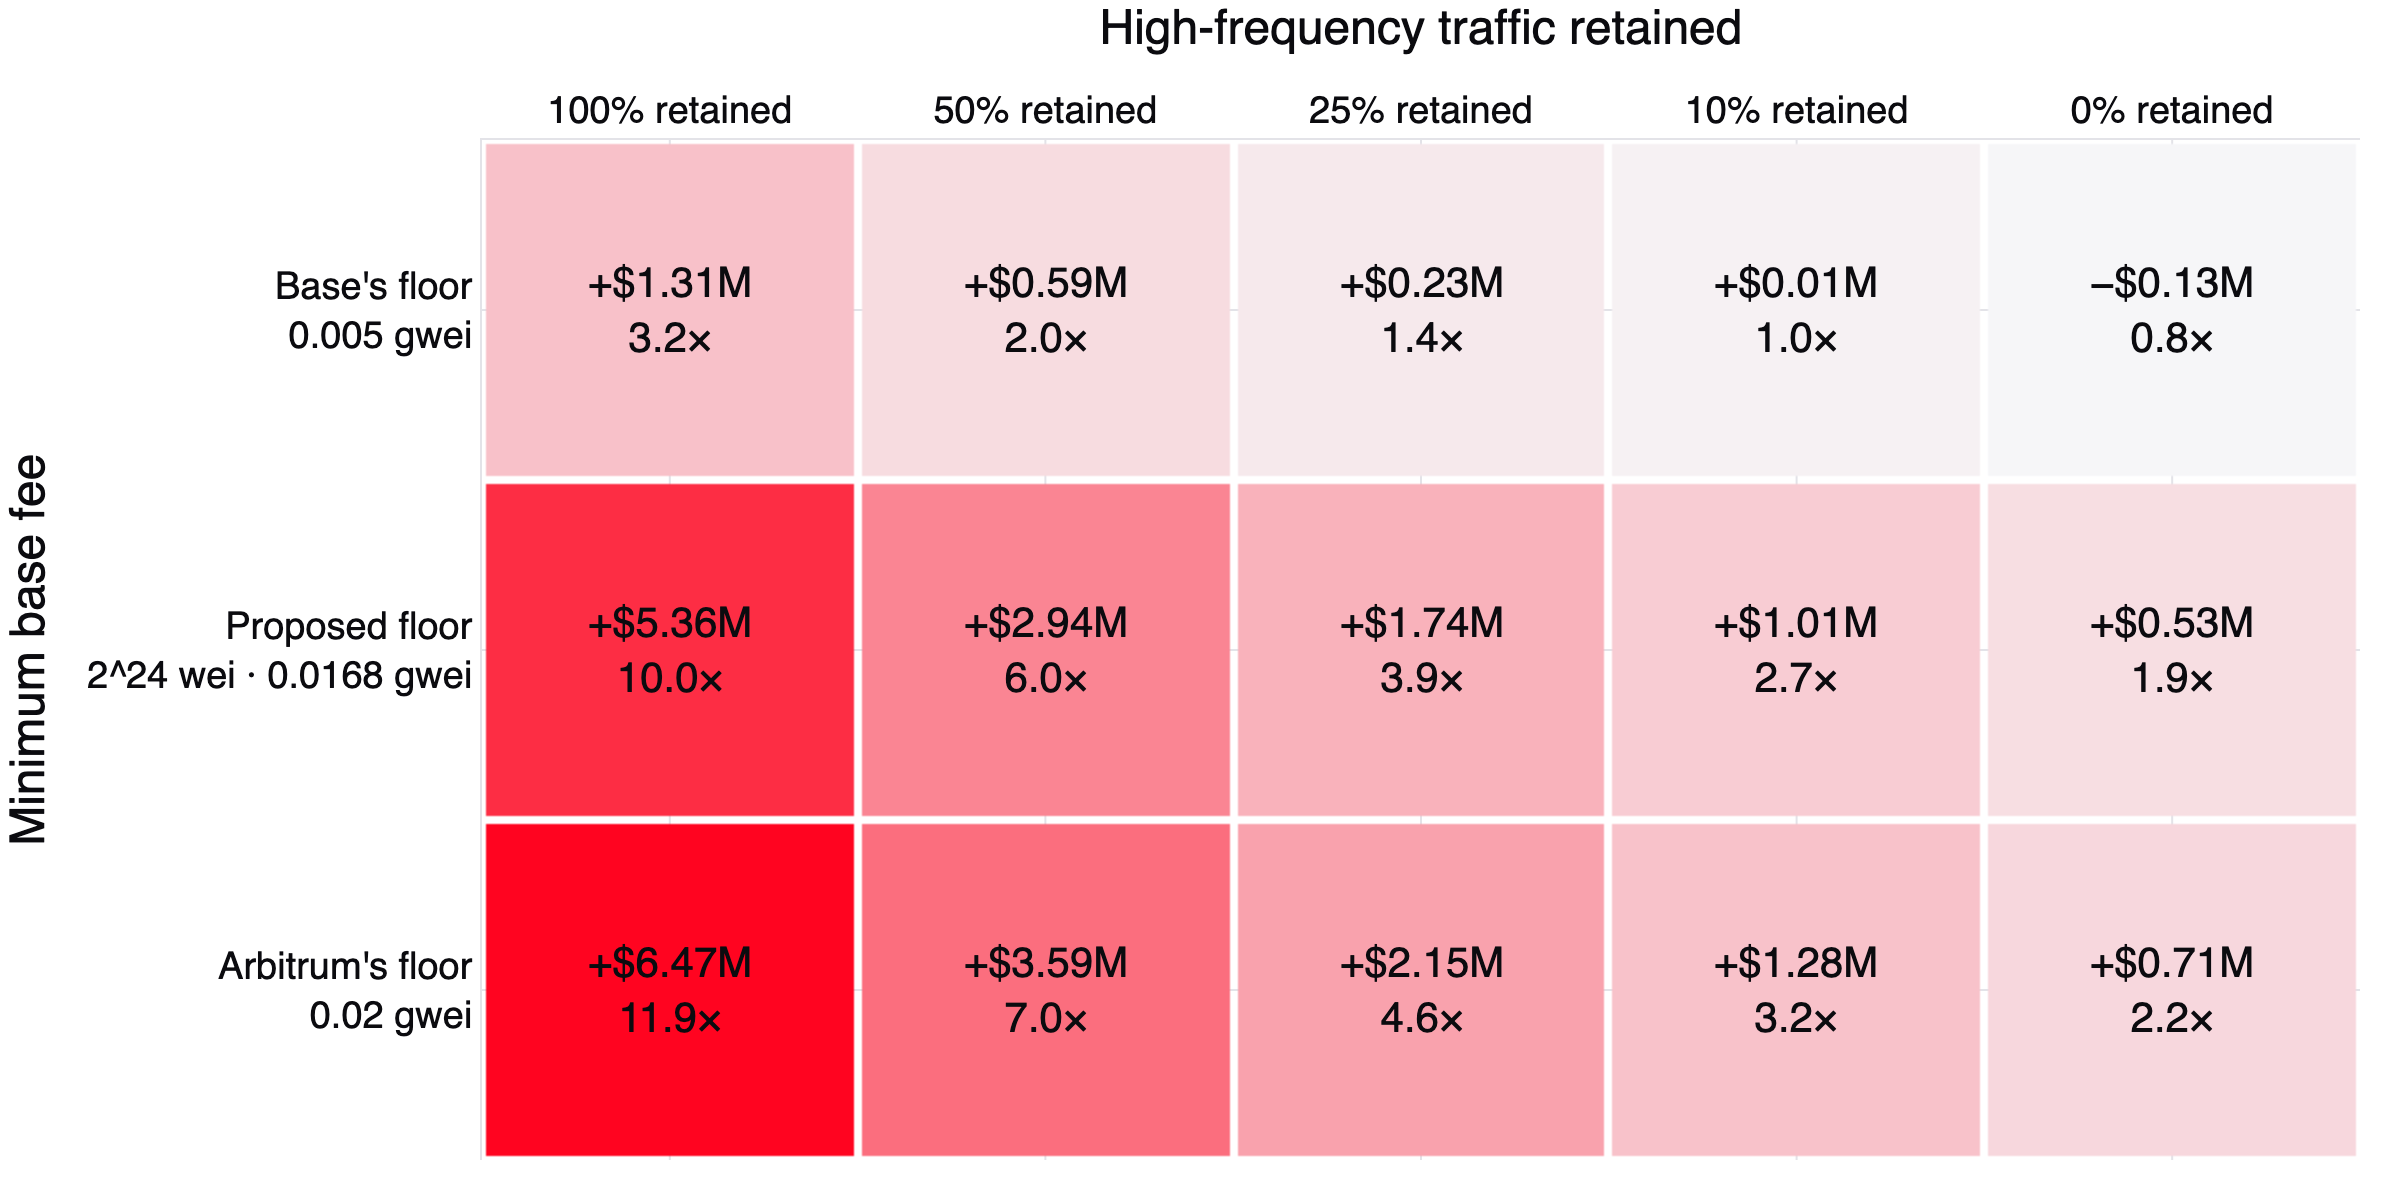

In [8]:
FLOOR_LABELS = {BASE_FLOOR_WEI: "Base's floor<br>0.005 gwei", FLOOR_WEI: "Proposed floor<br>2^24 wei · 0.0168 gwei", ARB_FLOOR_WEI: "Arbitrum's floor<br>0.02 gwei"}
RETENTION = [1.0, 0.5, 0.25, 0.1, 0.0]


def growth_sensitivity(theme: dict) -> go.Figure:
    fig = figure(theme)
    z = [[pick(r, f)["uplift_usd"] for r in RETENTION] for f in FLOOR_LABELS]
    mult = [[pick(r, f)["multiple"] for r in RETENTION] for f in FLOOR_LABELS]
    fig.add_heatmap(z=z, x=[f"{r:.0%} retained" for r in RETENTION], y=list(FLOOR_LABELS.values()),
                    colorscale=[[0, theme["surface"]], [1, theme["op"]]], showscale=False,
                    text=[[f"{'+' if v >= 0 else '−'}${abs(v)/1e6:.2f}M<br>{m:.1f}×" for v, m in zip(row, mrow)] for row, mrow in zip(z, mult)],
                    texttemplate="%{text}", textfont=dict(size=21, color=theme["ink"]), xgap=4, ygap=4)
    fig.update_layout(xaxis=dict(side="top", tickfont=dict(size=19, color=theme["ink"]), title="High-frequency traffic retained"),
                      yaxis=dict(autorange="reversed", tickfont=dict(size=19, color=theme["ink"]), title="Minimum base fee"),
                      margin=dict(l=20, r=20, t=60, b=20))
    return fig


show(growth_sensitivity)

## How much of the L1 cost did we charge users in June–August 2026, and what is closing the gap worth?

In [9]:
l1 = con.sql("""
    select sum(f.l1_data_fee_eth) / sum(r.value) as share_of_l1_cost_charged,
           (sum(r.value) - sum(f.l1_data_fee_eth)) * 365 / count(*) as l1_gap_eth_per_year,
           (sum(r.value) - sum(f.l1_data_fee_eth)) * 365 / count(*) * sum(f.total_fee_usd) / sum(f.total_fee_eth) as l1_gap_usd_per_year
    from fees_daily f
    join gtp_metrics r on r.date = f.date and r.origin_key = 'optimism' and r.metric_key = 'rent_paid_eth'
    where f.date between '2026-06-01' and '2026-08-31'
""").df()
numbers.record("growth_l1_recovery", l1["share_of_l1_cost_charged"][0], "Jun–Aug 2026 L1 data fee charged (file 01) / L1 cost paid (growthepie rent_paid_eth)")
numbers.record("growth_l1_gap_usd", l1["l1_gap_usd_per_year"][0], "annual gain from full L1 fee recovery: (growthepie rent_paid - L1 data fee charged), Jun–Aug 2026 x365/92, period price")
l1

,share_of_l1_cost_charged,l1_gap_eth_per_year,l1_gap_usd_per_year
0,0.256975,12.01577,22577.802191


## Lever 2: what is ether.fi's run-rate, and what is 50% more payments volume worth?

ether.fi grows by half, or a payments app half its size joins. Valued at today's price, so it is a floor-free lower bound.

In [10]:
payments = con.sql(f"""
    select sum(c.execution_fee_eth) * 365 / (select days from today) as etherfi_net_eth_per_year,
           sum(c.execution_fee_eth) * 365 / (select days from today) * {PAYMENTS_GROWTH} as payments_lever_eth
    from contract_activity c
    join m_customer_app m on m.address = c.to_address
    where m.app = 'etherfi' and c.date between '2026-06-01' and '2026-08-31'
""").df()
numbers.record("growth_etherfi_net_eth_per_year", payments["etherfi_net_eth_per_year"][0], "ether.fi Jun–Aug 2026 execution fees (net) annualised x365/92")
numbers.record("growth_lever_payments_growth", PAYMENTS_GROWTH, "payments lever base-case growth (low 0%, high 100%)")
payments

,etherfi_net_eth_per_year,payments_lever_eth
0,89.733413,44.866707


## Lever 3: what share of net revenue comes from trading customers, and what is 25% more trading worth?

Trading customers = the bots-and-automation, unlabeled (mostly priority bidders), DEX and exchange segments. Fees are assumed to move one for one with volume.

In [11]:
trading = con.sql(f"""
    select sum(c.execution_fee_eth) filter (where m.segment in ('bots_automation', 'unlabeled', 'dex', 'cex'))
               / sum(c.execution_fee_eth) as trading_share,
           (select net_eth_per_year from today) * trading_share * {TRADING_GROWTH} as trading_lever_eth
    from contract_activity c
    left join m_customer_app m on m.address = c.to_address
    where c.date between '2026-06-01' and '2026-08-31'
""").df()
numbers.record("growth_lever_trading_growth", TRADING_GROWTH, "trading lever base-case volume growth (low 0%, high 50%)")
numbers.record("growth_lever_trading_share", trading["trading_share"][0],
               "Jun–Aug 2026 share of net (execution fees) from segments bots_automation, unlabeled, dex, cex")
trading

,trading_share,trading_lever_eth
0,0.476487,37.629181


## Do fees really move with trading volume?

Monthly fees and DEX volume in ETH move together, but much of that is a shared downtrend, so one-for-one is an assumption, not an estimate.

In [12]:
dex = con.sql("""
    with m as (
        select date_trunc('month', f.date) as month, sum(f.total_fee_eth) as fee_eth, sum(d.v / f.eth_price_usd) as dex_eth, count(*) as days
        from fees_daily f
        join (select date, sum(total_volume_usd) as v from dex_volume group by date) d using (date)
        where f.date < '2026-09-01'  -- complete months only
        group by month
    )
    select corr(fee_eth, dex_eth) as fees_dex_corr,
           (sum(dex_eth) filter (where month between '2026-06-01' and '2026-08-01') / sum(days) filter (where month between '2026-06-01' and '2026-08-01'))
               / (sum(dex_eth) filter (where month between '2025-01-01' and '2025-03-01') / sum(days) filter (where month between '2025-01-01' and '2025-03-01'))
               - 1 as dex_eth_per_day_change
    from m
""").df()
numbers.record("growth_fees_dex_corr", dex["fees_dex_corr"][0],
               "Pearson correlation, monthly file 01 total fee ETH vs DEX volume in ETH (file 09 USD / daily price), Jan 2025–Aug 2026; largely a shared downtrend")
numbers.record("growth_dex_volume_eth_change", dex["dex_eth_per_day_change"][0], "DEX volume in ETH per day, Jun–Aug 2026 vs Jan–Mar 2025")
dex

,fees_dex_corr,dex_eth_per_day_change
0,0.943545,-0.734749


## What are the three recommendations worth, a year once in place?

1 = the 2^24 floor at 25% high-frequency retention plus full L1 recovery; 2 and 3 are valued at today's price. They are not fully additive (the floor also raises what payments and trading traffic pay), so adding them understates rather than double-counts.

In [13]:
levers = con.sql(f"""
    with l as (
        select 1 as n, 'pricing' as lever,
               (select uplift_eth from scenarios where floor_wei = {FLOOR_WEI} and botlike_retention = 0.25 and other_retention = 1)
                   + (select l1_gap_eth_per_year from l1) as eth_per_year
        union all
        select 2, 'payments', (select payments_lever_eth from payments)
        union all
        select 3, 'trading', (select trading_lever_eth from trading)
    )
    select n, lever, eth_per_year, eth_per_year * (select eth_usd from today) as usd_per_year
    from l
    order by n
""").df()
for r in levers.to_dict("records"):
    numbers.record(f"growth_lever_{r['lever']}_eth", r["eth_per_year"], {
        "pricing": "ETH a year: 2^24 floor full-year uplift at 25% high-frequency retention + full L1 fee recovery (run-rate)",
        "payments": "ETH a year: ether.fi Jun–Aug 2026 net run-rate x 50% growth (ether.fi grows by half, or a half-size payments app joins); today's price",
        "trading": "ETH a year: run-rate net x trading segments' share x 25% volume growth; fees assumed to move one for one with volume",
    }[r["lever"]])
    numbers.record(f"growth_lever_{r['lever']}_usd", r["usd_per_year"], f"growth_lever_{r['lever']}_eth at the Jun–Aug 2026 fee-weighted ETH price")
levers

,n,lever,eth_per_year,usd_per_year
0,1,pricing,935.777413,1.758339e+06
1,2,payments,44.866707,8.430518e+04
2,3,trading,37.629181,7.070576e+04


## Where does that take net revenue, from today to the target?

In [14]:
target = con.sql("""
    with l as (select sum(eth_per_year) as eth_per_year from levers)
    select t.net_eth_per_month as now_eth_per_month,
           t.net_eth_per_month + l.eth_per_year / 12 as target_eth_per_month,
           (t.net_eth_per_month + l.eth_per_year / 12) * 12 * t.eth_usd as target_usd_per_year,
           (t.net_eth_per_month + l.eth_per_year / 12) / t.net_eth_per_month as multiple
    from l, today t
""").df()
numbers.record("growth_net_eth_per_month_target", target["target_eth_per_month"][0], "now + (pricing + payments + trading levers) / 12")
numbers.record("growth_net_usd_per_year_target", target["target_usd_per_year"][0], "net a year with the three levers in place (25% case), Jun–Aug 2026 ETH price")
numbers.record("growth_target_multiple", target["multiple"][0], "net with the three levers / net today")
target

,now_eth_per_month,target_eth_per_month,target_usd_per_year,multiple
0,26.324059,111.180167,2.506909e+06,4.223519


## What would the floor cost ether.fi, our largest verified app?

ether.fi's transactions since 2026-04-09 at the 2^24 floor, against the revenue DefiLlama credits it with over the same days.

In [15]:
etherfi_at_floor_usd = con.sql(f"""
    select (sum(c.gas_used) * {FLOOR_WEI} / 1e18 + sum(c.l1_data_fee_eth)) * (select eth_usd from today)
    from contract_activity c
    join m_customer_app m on m.address = c.to_address
    where m.app = 'etherfi' and c.date >= '2026-04-09'
""").fetchone()[0]
etherfi_revenue = numbers.load()["cust_etherfi_app_revenue_usd"]["value"]
numbers.record("growth_etherfi_cost_share_at_floor", etherfi_at_floor_usd / etherfi_revenue,
               "ether.fi fees at the 2^24 floor since 2026-04-09 / DefiLlama revenue since 2026-04-09")
{"fees_at_floor_usd": etherfi_at_floor_usd, "app_revenue_usd": etherfi_revenue, "share": etherfi_at_floor_usd / etherfi_revenue}

{'fees_at_floor_usd': 240335.94222941058,
 'app_revenue_usd': 7058320.66,
 'share': 0.034050017533407244}

## What does the next 12 months look like, with 3 governance months before the 2^24 floor goes live?

Months 1–12 run from October 2026 to September 2027. Baseline = the run-rate, flat. With the floor, months 1–3 stay at the baseline, then the scenario's monthly net applies. USD at the June–August 2026 price, held flat.

In [16]:
path = con.sql(f"""
    with floor24 as (
        select botlike_retention, net_usd_per_year / 12 as usd_per_month
        from scenarios
        where floor_wei = {FLOOR_WEI} and other_retention = 1
    ), months as (
        select m.month_no,
               t.net_usd_per_year / 12 as baseline_usd,
               case when m.month_no <= {ACTIVATION_MONTHS} then t.net_usd_per_year / 12
                    else (select usd_per_month from floor24 where botlike_retention = 0) end as r0_usd,
               case when m.month_no <= {ACTIVATION_MONTHS} then t.net_usd_per_year / 12
                    else (select usd_per_month from floor24 where botlike_retention = 0.25) end as r25_usd,
               case when m.month_no <= {ACTIVATION_MONTHS} then t.net_usd_per_year / 12
                    else (select usd_per_month from floor24 where botlike_retention = 0.5) end as r50_usd
        from range(1, 13) m(month_no), today t
    )
    select month_no,
           strftime(date '2026-10-01' + to_months(month_no::int - 1), '%Y-%m') as month,
           baseline_usd, r0_usd, r25_usd, r50_usd,
           sum(baseline_usd) over (order by month_no) as cumulative_baseline_usd,
           sum(r0_usd) over (order by month_no) as cumulative_r0_usd,
           sum(r25_usd) over (order by month_no) as cumulative_r25_usd,
           sum(r50_usd) over (order by month_no) as cumulative_r50_usd
    from months
    order by month_no
""").df()
last = path.iloc[-1]
numbers.record("growth_12m_baseline_usd", last["cumulative_baseline_usd"], "sum of 12 baseline months (= growth_baseline_net_usd)")
for r in (0.25, 0.5):
    tag = f"r{int(r * 100)}"
    numbers.record(f"growth_12m_total_{tag}_usd", last[f"cumulative_{tag}_usd"],
                   f"12-month net, 2^24 floor live from month {ACTIVATION_MONTHS + 1}, {r:.0%} high-frequency retained")
    numbers.record(f"growth_month12_eth_per_day_{tag}", pick(r)["net_eth_per_day"], "month 12 net ETH per day = scenario annual net ETH / 365")
path

,month_no,month,baseline_usd,r0_usd,r25_usd,r50_usd,cumulative_baseline_usd,cumulative_r0_usd,cumulative_r25_usd,cumulative_r50_usd
0,1,2026-10,49463.279872,49463.279872,49463.279872,49463.279872,49463.279872,49463.279872,4.946328e+04,4.946328e+04
1,2,2026-11,49463.279872,49463.279872,49463.279872,49463.279872,98926.559743,98926.559743,9.892656e+04,9.892656e+04
2,3,2026-12,49463.279872,49463.279872,49463.279872,49463.279872,148389.839615,148389.839615,1.483898e+05,1.483898e+05
3,4,2027-01,49463.279872,93498.975540,194110.048638,294721.121736,197853.119486,241888.815155,3.424999e+05,4.431110e+05
4,5,2027-02,49463.279872,93498.975540,194110.048638,294721.121736,247316.399358,335387.790694,5.366099e+05,7.378321e+05
5,6,2027-03,49463.279872,93498.975540,194110.048638,294721.121736,296779.679230,428886.766234,7.307200e+05,1.032553e+06
6,7,2027-04,49463.279872,93498.975540,194110.048638,294721.121736,346242.959101,522385.741774,9.248300e+05,1.327274e+06
7,8,2027-05,49463.279872,93498.975540,194110.048638,294721.121736,395706.238973,615884.717314,1.118940e+06,1.621995e+06
8,9,2027-06,49463.279872,93498.975540,194110.048638,294721.121736,445169.518844,709383.692853,1.313050e+06,1.916717e+06
9,10,2027-07,49463.279872,93498.975540,194110.048638,294721.121736,494632.798716,802882.668393,1.507160e+06,2.211438e+06


## What does the cumulative 12-month path look like on a chart?

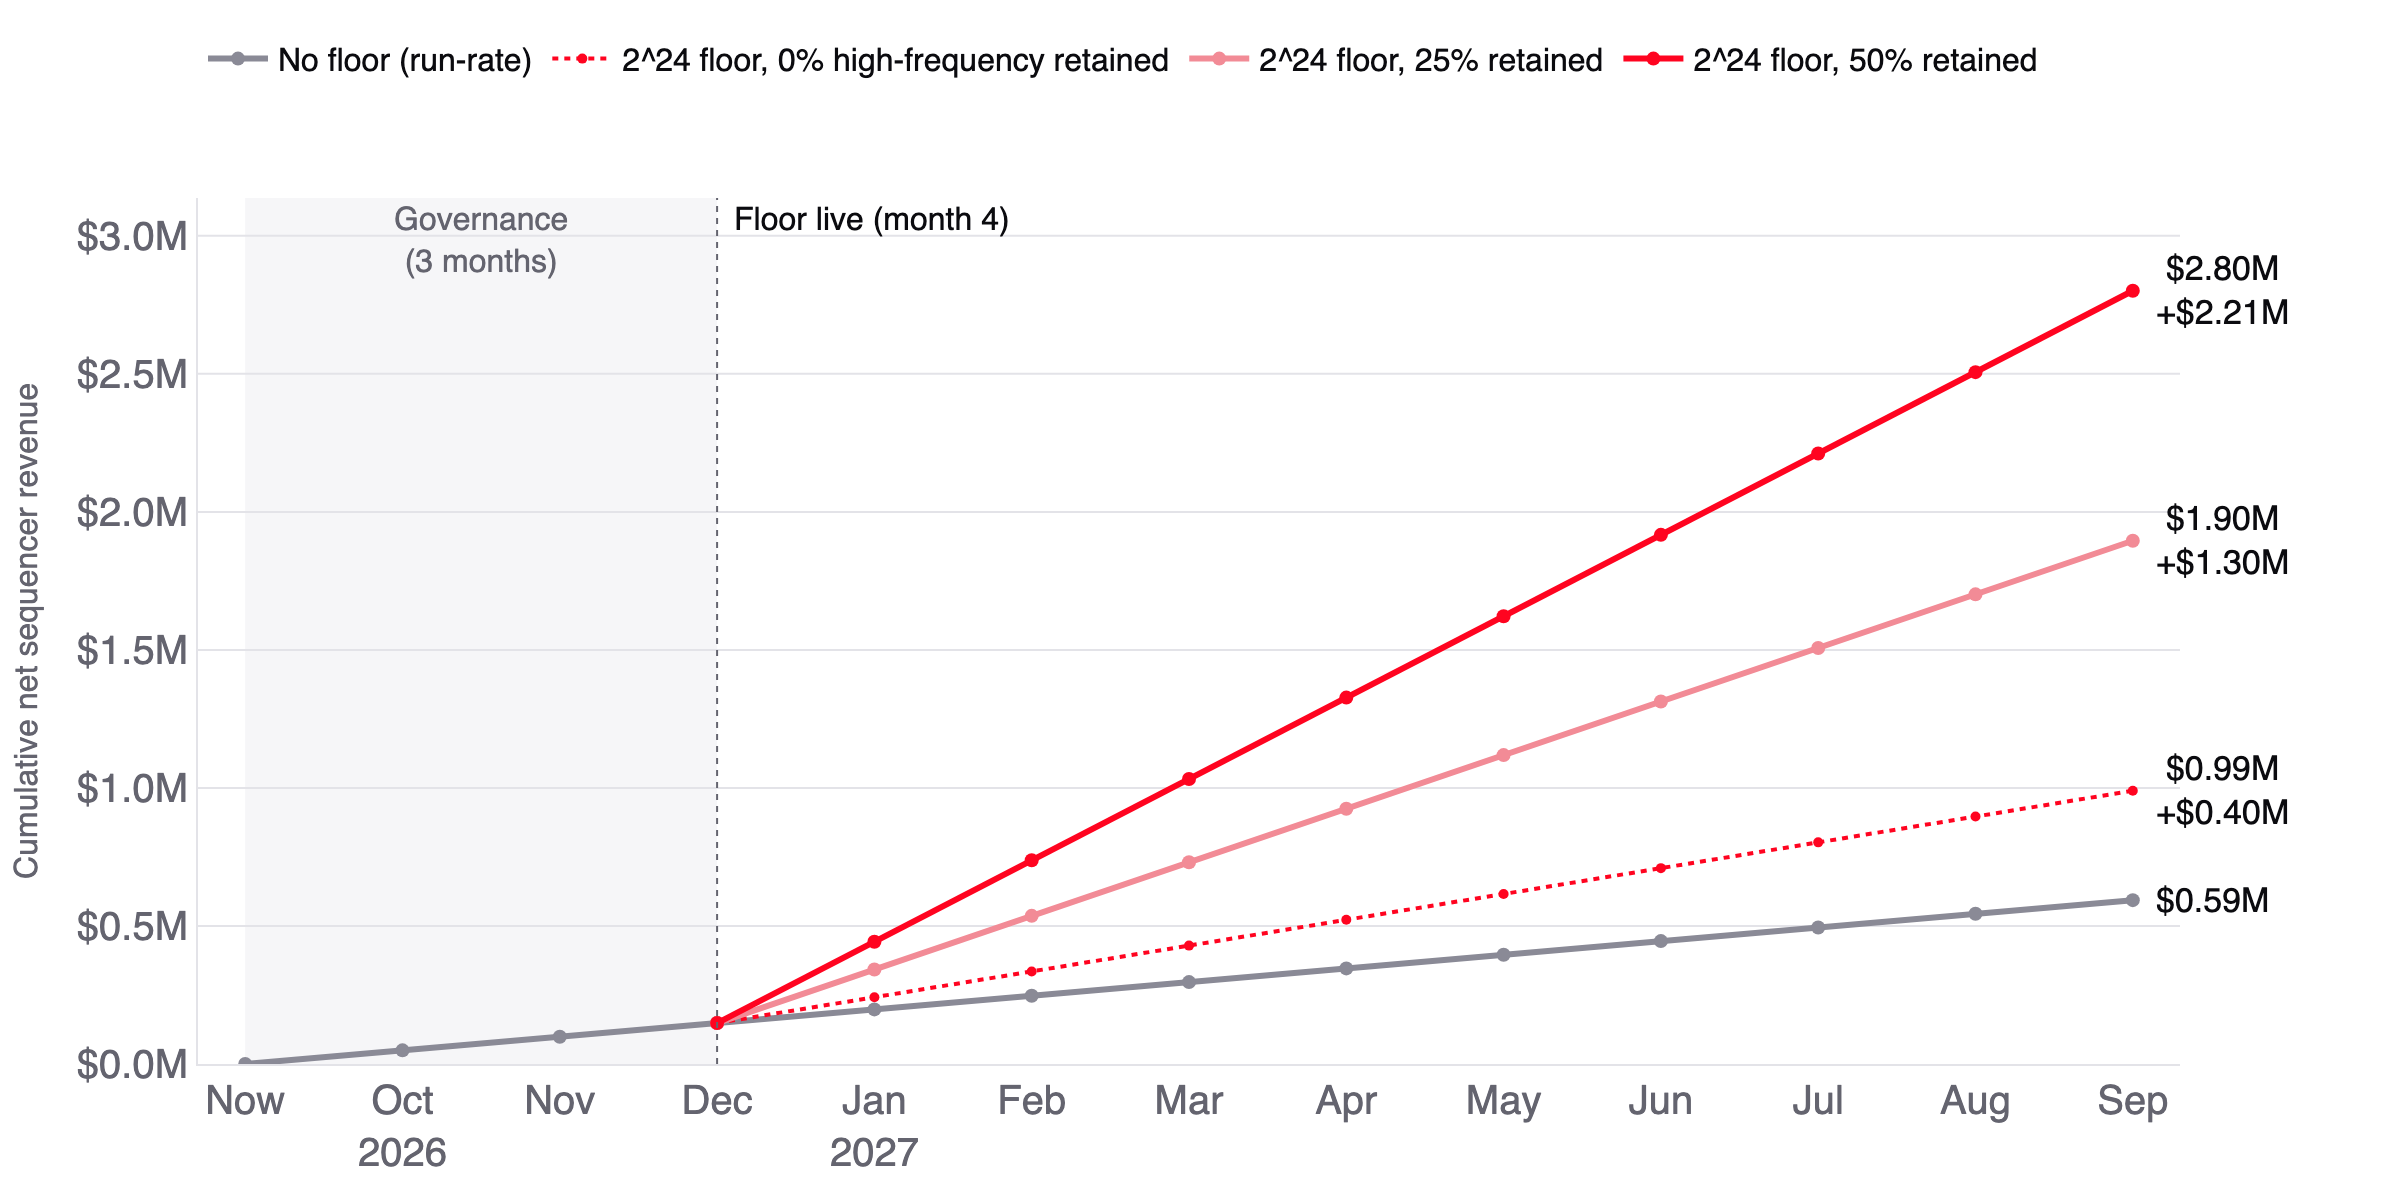

In [17]:
def growth_monthly_path(theme: dict) -> go.Figure:
    fig = figure(theme)
    x = [0] + path["month_no"].tolist()
    fig.add_vrect(x0=0, x1=ACTIVATION_MONTHS, fillcolor=theme["surface"], line_width=0, layer="below")
    fig.add_annotation(x=ACTIVATION_MONTHS / 2, y=1, yref="paper", yanchor="top", showarrow=False,
                       text=f"Governance<br>({ACTIVATION_MONTHS} months)", font=dict(size=16, color=theme["muted"]))
    fig.add_vline(x=ACTIVATION_MONTHS, line=dict(color=theme["muted"], width=1, dash="dot"))
    fig.add_annotation(x=ACTIVATION_MONTHS, y=1, yref="paper", yanchor="top", xanchor="left", xshift=6, showarrow=False,
                       text=f"Floor live (month {ACTIVATION_MONTHS + 1})", font=dict(size=16, color=theme["ink"]))
    base_total = path["cumulative_baseline_usd"].iloc[-1]
    series = (("baseline", "No floor (run-rate)", theme["series"][2], "solid"),
              ("r0", "2^24 floor, 0% high-frequency retained", theme["op"], "dot"),
              ("r25", "2^24 floor, 25% retained", theme["series"][4], "solid"),
              ("r50", "2^24 floor, 50% retained", theme["op"], "solid"))
    for key, name, color, dash in series:
        start = 0 if key == "baseline" else ACTIVATION_MONTHS  # scenarios branch off the baseline when the floor goes live
        y = ([0.0] + path[f"cumulative_{key}_usd"].tolist())[start:]
        fig.add_scatter(x=x[start:], y=y, name=name, mode="lines+markers", line=dict(color=color, width=3 if dash == "solid" else 2, dash=dash),
                        marker=dict(size=7 if dash == "solid" else 5, color=color))
        label = f"&#36;{y[-1] / 1e6:.2f}M" + ("" if key == "baseline" else f"<br>+&#36;{(y[-1] - base_total) / 1e6:.2f}M")  # entity: two $ would trigger LaTeX
        fig.add_annotation(x=12, y=y[-1], xanchor="left", xshift=10, showarrow=False, text=label, font=dict(size=17, color=theme["ink"]))
    ymax = path["cumulative_r50_usd"].max() * 1.12
    ticks = [v * 500_000 for v in range(int(ymax // 500_000) + 1)]
    months = path["month"].tolist()
    fig.update_layout(margin=dict(l=70, r=110, t=90, b=60), legend=dict(y=1.2, font_size=16),
                      xaxis=dict(tickvals=x, ticktext=["Now"] + [calendar.month_abbr[int(m[5:])] + (f"<br>{m[:4]}" if m.endswith(("-10", "-01")) else "") for m in months],
                                 showgrid=False, range=[-0.3, 12.3]),
                      yaxis=dict(range=[0, ymax], tickvals=ticks, ticktext=[f"${v / 1e6:.1f}M" for v in ticks],
                                 title=dict(text="Cumulative net sequencer revenue", font=dict(size=16, color=theme["muted"]))))
    return fig


show(growth_monthly_path)